In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

import os
from itertools import product
from tqdm.notebook import tqdm
from functools import partial

import pandas as pd
import numpy as np
from schnetpack.md.data import HDF5Loader

from matplotlib import pyplot as plt

from imlff.loading import load_model_from_wandb
from imlff.md.util import desc_md, load_update_desc_model
from imlff.common.util import proj_path
from imlff.model.solvers import fixed_point_iteration
from imlff.data.info import md17_conformations_per_molecule, md22_conformations_per_molecule
from imlff.analysis.plotting import \
    convergence_plots, read_degrees_and_model_tags, \
    scatter_plot, create_scatter_df, \
    get_colour_by_degree, get_label_by_regularisation, \
    get_colour_by_regularisation, get_label_by_degree

In [ ]:
pat = proj_path('result_summary/january-22/param_search_aspirin_test.csv')
runs_df = pd.read_csv(pat).sort_values(['jac_reg_strength', 'fpc_strength', 'trunc_strength'])

In [55]:
deep = 'both'
deep = False
deep = True

molecule = 'aspirin'
# molecule = 'benzene'
molecule = 'from_df', 'result_summary/january-07/best_runs_per_group.csv', ' and molecule=="aspirin" and AtomisticRepresentationClass=="PaiNN" and n_z==128'

molecule = 'from_df', 'result_summary/january-07/best_runs_per_group.csv', ''
molecule_postfix = ''

molecule = 'param_search', ' and jac_reg_strength==0.32'
molecule = 'param_search', ''

molecule = 'param_search_new', ''
molecule = 'Ac-Ala3-NHMe'

setups = model_tags = molecules_and_mts = ws_degrees = None

temperatures = [300, 500]

if molecule == 'aspirin':
    model_tags = runs_df['latest_tag']
    if deep == 'both':
        model_tags = ['model-6nf8mqsm:v579'] + list(model_tags)
    elif deep == True:
        model_tags = ['model-6nf8mqsm:v579']
        
    tolerances = [0, 0.001, 0.01]

    molecule_postfix = '-run-1'
    
elif molecule == 'benzene':
    model_tags = ['model-g51tassj:v499']
    tolerances = [0.01]
    
elif molecule == 'Ac-Ala3-NHMe':
    model_tags = ['model-4ehmqw9w:v3392']
    tolerances = [0.01]
    tolerances = [0.001]
    
    tolerances = [0, 0.001, 0.01]
    
    ws_degrees = [-1, 0, 1]
    temperatures = [100, 200, 300, 400, 500, 600]

elif 'from_df' in molecule:
    tolerances   = [0.01]
    runs_df_all = pd.read_csv(proj_path(molecule[1])).query('type=="deq"' + molecule[2])
    molecules_and_mts = runs_df_all[['molecule', 'latest_tag']].to_numpy()
    
elif 'param_search' in molecule:
    tolerances   = [0, 0.001, 0.01]
    molecules_and_mts = runs_df.query('type=="deq"' + molecule[1])[['molecule', 'latest_tag']].to_numpy()
    
elif 'param_search_new' in molecule:
    tolerances   = [0.01]
    runs_df_new = pd.read_csv(proj_path('result_summary/runs/april-22_aspirin_param_search/runs_df_val_test.csv'))
    molecules_and_mts = runs_df_new.query('type=="deq"' + molecule[1])[['molecule', 'best_manual_tag']].to_numpy()
    ws_degrees = [-1]
    temperatures = [300]
        
setups = list(product(
    [False], # dev
    molecules_and_mts if molecules_and_mts is not None else \
        [(molecule, mt) for mt in model_tags], # molecule names, model tags
    temperatures,
    tolerances,
    ws_degrees if ws_degrees is not None else  [-1, 0, 1] + bool(deep) * [2, 3, 4], # warmstart degrees
    range(10), # seeds
))

In [57]:
# depend on global ws_degrees, runs_df

def get_ws_label(warmstart_degree, brackets=True, warmstart_str=" warmstart"):
    if warmstart_degree < 0:
        if brackets:
            return ""
        return "No" + warmstart_str
    
    if warmstart_degree == 0:    
        l = f"const."
    elif warmstart_degree == 1:    
        l = f"linear"
    else:    
        l = f"deg={warmstart_degree}"
    
    if brackets:
        return f" ({l})"
    return l + warmstart_str

colour_dicts = {}
for col, colour_map in zip(
    ['jac_reg_strength', 'fpc_strength', 'trunc_strength'],
    ['Blues', 'Reds', 'Greens']
):
    unique_vals = sorted(runs_df[col].unique())
    colours = [tuple(c) for c in plt.get_cmap(colour_map)(np.linspace(0.3, 0.9, len(unique_vals)))]
    colour_dicts[col] = dict(zip(unique_vals, colours))
    
def get_linestyle(warmstart_degree):
    try:
        linestyle = {
            -1: '-.',
            0: ':',
            1: '-',
            2: '--',
            3: (0, (3, 1, 1, 1)),
            4: (0, (5, 1)),
        }[warmstart_degree]
    except Exception as e:
        linestyle = '-'
    return linestyle

def get_colour_and_label_deep(model_tag, warmstart_degree, ws_degrees=[-1,0,1,2,3,4], **kwargs):
    colour = 'black'
    label = get_ws_label(warmstart_degree, brackets=False, **kwargs) or 'No warmstart'
    
    unique_vals = sorted(ws_degrees)
    if warmstart_degree in unique_vals:
        colour = plt.cm.viridis(unique_vals.index(warmstart_degree) / (len(unique_vals)-.999)) # avoid div by zero
    else:
        label += ' - unknown'
        
    try:
        row = runs_df.query(f"latest_tag.str.contains({model_tag.split('/')[-1].split(':')[0]!r})")
        if len(row)==0:
            print(model_tag)
        if len(row)>1:
            print(row)
        fmae = row['latest__test_forces_MAE'].item() 
        label += f' |%%| {fmae:>2.2f}'
    except Exception as e:
        print(e)
        print()
        label += f' |%%| fmae not found'
    
    return colour, label


def get_colour_and_label_broad(model_tag, warmstart_degree):
    def format_sci(val):
        return f"{val:.0e}"

    def format_j(val):
        s = f"{val:.3f}"
        zeros = len(s) - len(s.rstrip("0"))
        s_trim = s.rstrip("0")
        if s_trim.endswith("."):
            s_trim = s_trim[:-1]
        if "." not in s_trim:
            s_trim += "."
        return s_trim + (" " * zeros)

    row = runs_df.query(f"latest_tag.str.contains({model_tag.split('/')[-1].split(':')[0]!r})")
    if len(row)!=1:
        print(model_tag)
        # print(row)

    f, t, j = row['fpc_strength'].item(), row['trunc_strength'].item(), row['jac_reg_strength'].item()
    assert sum([np.isnan(f), np.isnan(t), np.isnan(j)]) >= 2, f"More than one of fpc, trunc, jac_reg is non-zero for {model_tag}"
    
    
    
    if j > 0:
        colour = colour_dicts["jac_reg_strength"][j]
        label = f"jac:{format_j(j).rjust(5)}"
    elif f > 0:
        colour = colour_dicts["fpc_strength"][f]
        label = f"fpc:{format_sci(f).rjust(5)}"
    elif t > 0:
        colour = colour_dicts["trunc_strength"][t]
        label = f"trunc:{format_sci(t).rjust(5)}"
    else:
        colour = 'black'
        label = "No Reg.:" + ' '*5
       
    # add fmae performance
    fmae = row['latest__test_forces_MAE'].item() 
    label += f' |%%| {fmae:>2.2f}'
        
    # denote which warmstart
    label += get_ws_label(warmstart_degree)
        
    return colour, label

In [63]:
if 0 or 'data_forw' not in locals(): # want to just add something?
    data_forw = dict()
    data_back = dict()
    data_forw_b = dict()
    data_back_b = dict()

for dev, (molecule_name, model_tag), target_temperature, tol, warmstart_degree, seed in tqdm(setups[:]):

    target_forw = data_forw.setdefault((target_temperature, tol), dict()).setdefault((model_tag, warmstart_degree), dict())
    target_back = data_back.setdefault((target_temperature, tol), dict()).setdefault((model_tag, warmstart_degree), dict())
    target_forw_b = data_forw_b.setdefault(tol, dict()).setdefault((model_tag, warmstart_degree), dict()).setdefault((target_temperature), dict())
    target_back_b = data_back_b.setdefault(tol, dict()).setdefault((model_tag, warmstart_degree), dict()).setdefault((target_temperature), dict())
    
    
    if  1000==len(target_forw.get(seed, [])) \
    and 1000==len(target_back.get(seed, [])) \
    and 1000==len(target_forw_b.get(seed, [])) \
    and 1000==len(target_back_b.get(seed, [])):
        continue
    
    
    tol = float(tol)
    if model_tag.startswith('model-'):
        model_tag = 'qcml-group/dev-v10/' + model_tag
    model = load_model_from_wandb(model_tag)
    model_config = dict(
        model_tag=model_tag,
        implicit_diff=True,
        
        forw_tol=tol,
        back_tol=tol,
        
        forw_solver=fixed_point_iteration,
        back_solver=fixed_point_iteration,
        forw_max_iter=10,
        back_max_iter=10,
        warmstart_configs=dict(z=warmstart_degree, g_bar=warmstart_degree) if warmstart_degree>=0 else None,
    )
    model, model_config_description = load_update_desc_model(model=model, **model_config)
    
    np.random.seed(seed)
    n_conformations = md17_conformations_per_molecule.get(molecule_name, md22_conformations_per_molecule.get(molecule_name))
    assert n_conformations is not None, f"Unknown molecule: {molecule_name}"
    molecule_config = dict(
        molecule_name = molecule_name,
        molecule_idx = np.random.randint(0, n_conformations),
        strategy = 1,
        initial_temperature = 500,
        target_temperature = target_temperature,
    )

    for molecule_postfix in ['', '-run-1']:
        setup_path = proj_path('results-dev-te' if dev==True else 'results', f"iter_count/s{molecule_config['strategy']}/{molecule_config['molecule_name']}{molecule_postfix}/T{molecule_config['target_temperature']:04d}K_iT{molecule_config['initial_temperature']:04d}K/{molecule_config['molecule_idx']}/")
        md_log_path = setup_path + desc_md(timestep=0.5,) + '__' + model_config_description + '.hdf5'
        
        if os.path.exists(md_log_path):
            break
        else:
            print('Does not exist:')
            print(md_log_path)
            
    else:
        print('No path variants exist.')
        continue
    
    with HDF5Loader(md_log_path, skip_initial=0) as data:
        pass # once exiting the context 'data'' is not writable but readable.

    forw_all_iters = []
    back_all_iters = []
    for s, all_iters in [('forw', forw_all_iters), ('back', back_all_iters)]:
        for i in range(1, 11):
            one_iter = data.get_property(f'{s}_res_{i:02d}', atomistic=False)
            if len(one_iter) < 1000:
                print(f"Only {len(one_iter)} steps for {s} with tol {tol}, temp {target_temperature}, seed {seed}, warmstart {warmstart_degree}")
                continue
            all_iters.append(one_iter)
    
    target_forw[seed] = forw_all_iters
    target_back[seed] = back_all_iters
    
    target_forw_b[seed] = forw_all_iters
    target_back_b[seed] = back_all_iters

#### Check

In [64]:
## check if all seeds were there

for (temp, tol), ddd in data_forw.items():
    for (mt, deg), dat in ddd.items():
        if '' in mt: # filter?
            found = []
            for k, v in dat.items():
                l =  len(v)
                if l<10:
                    found.append((k, l))
                    
                for arr in v:
                    if len(arr)<1000:
                        print(len(arr))
                    
            if found:
                print(temp, tol, mt, deg)
                for k,l in found:
                    print(' ', k, l)

In [65]:
for k,dic in data_back.items():
    print(k)
    for kk in dic.keys():
        print('\t', kk, len(dic[kk]), [len(r) for r in dic[kk].values()])

(300, 0.01)
	 ('model-6f9rdcuh:v279', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-21vok9wk:v399', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-2brhxooj:v319', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-2lrd61mw:v760', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-3n0qsrkj:v566', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-44onx3ok:v699', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-4ifpi8o0:v279', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-5gw5wjtm:v419', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-6nf8mqsm:v359', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-77tz9pux:v15', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-7gmda78n:v1829', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-85qii01z:v22', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-982x29rp:v279', -1) 10 [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
	 ('model-a7tdvqip:v319', -

In [66]:

all_degrees,all_model_tags = read_degrees_and_model_tags(data_forw)
print('ws degrees (all):', all_degrees)
print('model_tags (all):', all_model_tags)
print('temperatures (in first):', data_forw_b[k:=next(iter(data_forw_b))][next(iter(data_forw_b[k]))].keys())

ws degrees (all): [-1]
model_tags (all): ['model-21vok9wk:v399', 'model-2brhxooj:v319', 'model-2lrd61mw:v760', 'model-3n0qsrkj:v566', 'model-44onx3ok:v699', 'model-4ifpi8o0:v279', 'model-5gw5wjtm:v419', 'model-6f9rdcuh:v279', 'model-6nf8mqsm:v359', 'model-77tz9pux:v15', 'model-7gmda78n:v1829', 'model-85qii01z:v22', 'model-982x29rp:v279', 'model-a7tdvqip:v319', 'model-belcry1p:v21', 'model-f8ahb02o:v119', 'model-g98xmm0c:v505', 'model-h8hjhaid:v19', 'model-jn55xadh:v139', 'model-k4r3p1kb:v11', 'model-m8zif6kt:v319', 'model-mucdc6d4:v89', 'model-nclpq8xw:v943', 'model-o8hfesjq:v139', 'model-shxw1phd:v574', 'model-sle53u87:v13', 'model-soh06exs:v239', 'model-tsncmgt5:v259', 'model-vak5cqic:v419', 'model-vp26tqb2:v139', 'model-vzu4mpzd:v15', 'model-xs6feire:v374', 'model-y5y3o1oi:v17', 'model-z7vpbbzm:v377', 'model-zkqsnmgj:v685']
temperatures (in first): dict_keys([300])


## Temperature to Iter

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

[100, 200, 300, 400, 500, 600]
~/imlff/../imlff-paper/figures/convergence-speed/temperature-0.001w0.0_0.001_0.001w0.01.pdf


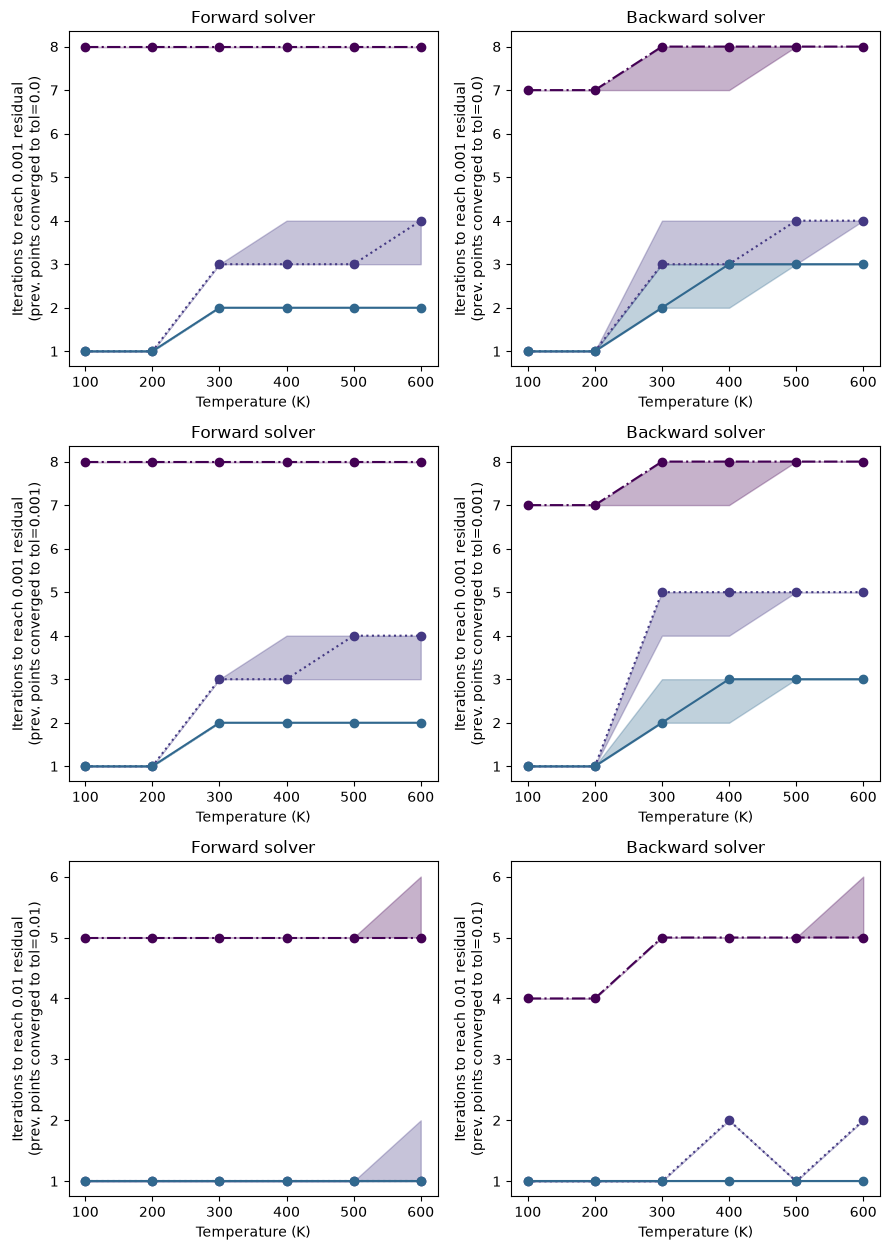

In [59]:
tols_thresholds = [
    (0.,    0.001),
    (0.001, 0.001),
    (0.01,  0.001),
]
show_warmstart_degrees = [-1,0,1]

s = .6
n_rows = len(tols_thresholds)
fig, axs = plt.subplots(n_rows, 2, figsize=(s*15,s*7*n_rows))
col1, col2 = np.array(axs).T


for all_tols, title, ax_col in [(data_forw_b, 'Forward solver', col1), (data_back_b, 'Backward solver', col2)]:
    ax_col = ax_col if n_rows > 1 else [ax_col]
    for ax, (tol, threshold) in zip(ax_col, tols_thresholds):
        all_models = all_tols[tol]
        all_temp = set()
        for (model_tag, warmstart_degree), all_temperatures in all_models.items():
            temp, middle, up, down = [], [], [], []
            for temperature, all_seeds in sorted(all_temperatures.items()):

                if not (warmstart_degree in show_warmstart_degrees):
                    continue
                
                residuals = np.array(list(all_seeds.values())).transpose((1,0,2)).reshape((10, -1))
                residuals[0] = np.inf
                residuals = np.nan_to_num(residuals, nan=tol)
                if threshold<tol:
                    print(f"Warning: threshold {threshold} < tol {tol} - residuals below tol are not available. Changing threshold to tol.")
                    threshold = tol
                below_threshold = residuals <= threshold
                has_hit = below_threshold.any(axis=0)
                idx_first_below_threshold = np.where(has_hit, below_threshold.argmax(axis=0), len(residuals)) # (10 if never)
                
                d, m, u = np.percentile(idx_first_below_threshold, [5, 50, 95])
                all_temp.add(temperature)
                temp.append(temperature)
                down.append(d)
                middle.append(m)
                up.append(u)
                
            colour = get_colour_by_degree(warmstart_degree=warmstart_degree)
            label = get_label_by_degree(model_tag=model_tag, warmstart_degree=warmstart_degree, runs_df=runs_df)
            linestyle = get_linestyle(warmstart_degree)
            ax.fill_between(temp, down, up, alpha=0.3, color=colour)
            ax.plot(temp, middle, label=label, color=colour, linestyle=linestyle, marker='o')
            
            ax.set_xlabel('Temperature (K)')
            ax.set_ylabel(f'Iterations to reach {threshold} residual\n(prev. points converged to tol={tol})')
            ax.set_title(title)
        ax.set_xticks(list(all_temp))
        print(sorted(all_temp))
else:
    for ax in ax_col:
        continue
        ax.legend()
        
plt.tight_layout()

config_str = '_'.join([f'{thresh}' + f'w{tol}' * (tol!=thresh) for (tol, thresh) in tols_thresholds])
pat = proj_path('../imlff-paper/figures/convergence-speed/') + f'temperature-{config_str}.pdf'
fig.savefig(pat, bbox_inches='tight')
print(pat)
        
# make ax[0][0] stretch over entire fig:
# axs[0][1].remove()
# axs[1][0].remove()
# axs[1][1].remove()
# axs[0][0].set_xlim(230, 260)

plt.show()


In [50]:
all_tols.keys()

dict_keys([0.001, 0, 0.01])

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

~/imlff/../imlff-paper/figures/convergence-speed/temperature-0.001_0.01-merged.pdf


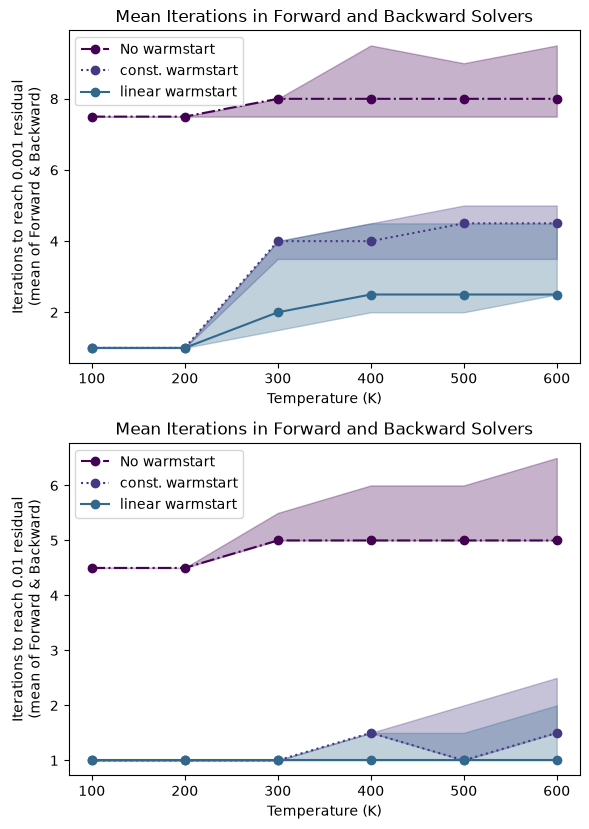

In [64]:
show_warmstart_degrees = [-1,0,1]

tols_thresholds = [
    # (0.0, 0.0),
    (0.001, 0.001),
    (0.01, 0.01),
]

percentiles_to_plot = [5, 50, 95]
percentiles_to_plot = [0, 50, 100]


# ============ OPTION 2: Combined mean plot ============
s = .6
n_rows = len(tols_thresholds)
if True:
    fig2, axs2 = plt.subplots(n_rows, 1, figsize=(s*10, s*7*n_rows))
    axs2 = [axs2] if n_rows == 1 else axs2
else:
    from brokenaxes import brokenaxes
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec

    fig2 = plt.figure(figsize=(s*10, s*7*n_rows))
    gs = GridSpec(n_rows, 1, figure=fig2)

    axs2 = []
    for i in range(n_rows):
        bax = brokenaxes(
            ylims=((0, 4.3), (7, 10)),  # adjust these ranges as needed
            subplot_spec=gs[i],
            fig=fig2
        )
        axs2.append(bax)


for ax, (tol, thresh) in zip(axs2, tols_thresholds):
    
    # Store data from both solvers
    combined_data = {}
    
    for all_tols, solver_name in [(data_forw_b, 'Forward'), (data_back_b, 'Backward')]:
        all_models = all_tols[tol]
        
        for (model_tag, warmstart_degree), all_temperatures in all_models.items():
            key = (model_tag, warmstart_degree)
            if key not in combined_data:
                combined_data[key] = {'temp': [], 'middle': [], 'down': [], 'up': []}
            
            if not (warmstart_degree in show_warmstart_degrees):
                continue
            
            for temperature, all_seeds in sorted(all_temperatures.items()):
                residuals = np.array(list(all_seeds.values())).transpose((1,0,2)).reshape((10, -1))
                residuals[0] = np.inf
                residuals = np.nan_to_num(residuals, nan=tol)
                if thresh<tol:
                    print(f"Warning: threshold {thresh} < tol {tol} - residuals below tol are not available. Changing threshold to tol.")
                    thresh = tol
                
                below_threshold = residuals <= thresh
                has_hit = below_threshold.any(axis=0)
                idx_first_below_threshold = np.where(has_hit, below_threshold.argmax(axis=0), len(residuals))
                
                d, m, u = np.percentile(idx_first_below_threshold, percentiles_to_plot)
                
                combined_data[key]['temp'].append(temperature)
                combined_data[key]['middle'].append(m)
                combined_data[key]['down'].append(d)
                combined_data[key]['up'].append(u)
    
    # Average Forward and Backward
    all_temp = set()
    for (model_tag, warmstart_degree), data in combined_data.items():
        if not (warmstart_degree in show_warmstart_degrees):
            continue
        # Group by temperature and average
        temp_dict = {}
        for t, m, d, u in zip(data['temp'], data['middle'], data['down'], data['up']):
            if t not in temp_dict:
                temp_dict[t] = {'middle': [], 'down': [], 'up': []}
            temp_dict[t]['middle'].append(m)
            temp_dict[t]['down'].append(d)
            temp_dict[t]['up'].append(u)
        
        temp = sorted(temp_dict.keys())
        middle = [np.mean(temp_dict[t]['middle']) for t in temp]
        down = [np.mean(temp_dict[t]['down']) for t in temp]
        up = [np.mean(temp_dict[t]['up']) for t in temp]
        
        colour = get_colour_by_degree(warmstart_degree=warmstart_degree)
        label = get_label_by_degree(model_tag=model_tag, warmstart_degree=warmstart_degree, runs_df=runs_df)
        label = label.split(' |')[0]
        linestyle = get_linestyle(warmstart_degree=warmstart_degree)
        ax.fill_between(temp, down, up, alpha=0.3, color=colour)
        ax.plot(temp, middle, label=label, color=colour, linestyle=linestyle, marker='o')
        all_temp.update(temp)
    
    ax.set_xlabel('Temperature (K)')
    ax.set_ylabel(f'Iterations to reach {thresh} residual\n(mean of Forward & Backward)')
    ax.set_title('Mean Iterations in Forward and Backward Solvers')
    ax.set_xticks(sorted(all_temp))
    ax.legend()

plt.tight_layout()
    
config_str = '_'.join([f'{thresh}' + f'w{tol}' * (tol!=thresh) for (tol, thresh) in tols_thresholds])
pat = proj_path('../imlff-paper/figures/convergence-speed/') + f'temperature-{config_str}-merged.pdf'
fig2.savefig(pat)
print(pat)

plt.show()


## Step to residual

In [68]:
from collections import defaultdict

data_both = defaultdict(dict)

for (T, tol) in data_forw:
    for (mt, deg) in data_forw[(T, tol)]:
        forw = data_forw[(T, tol)][(mt, deg)]
        back = data_back[(T, tol)][(mt, deg)]
        
        data_both[(T, tol)][(mt, deg)] = {
            seed: np.nanmean(np.stack([forw[seed], back[seed]]), axis=0)
            for seed in forw
        }

/tmp/ipykernel_3203288/2983593942.py:11: RuntimeWarning: Mean of empty slice
  seed: np.nanmean(np.stack([forw[seed], back[seed]]), axis=0)


### - New

~/imlff/../imlff-paper/figures/losses_to_convergence_speed_temp=300K_tol=0.01_ws=-1_merged_clean.pdf
~/imlff/../imlff-paper/figures/losses_to_convergence_speed_v_fmae_scatter_temp=300K_tol=0.01_ws=-1_merged.pdf


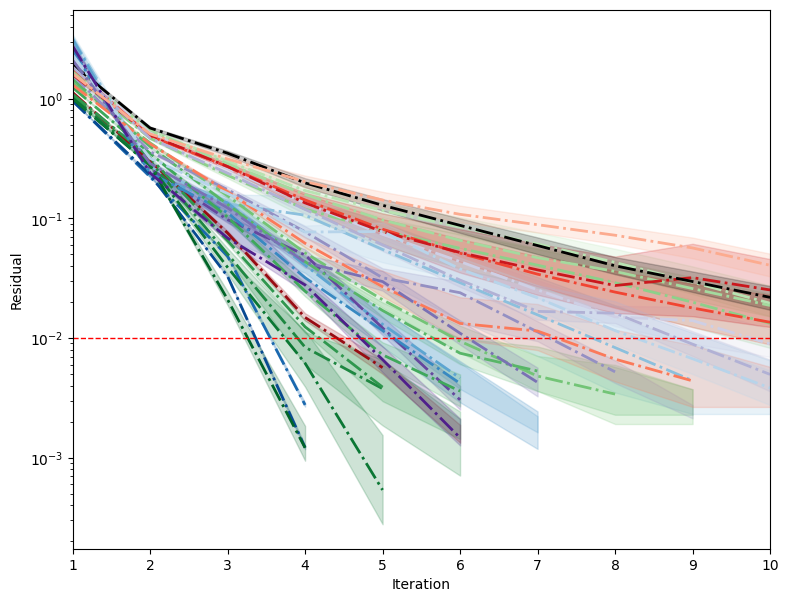

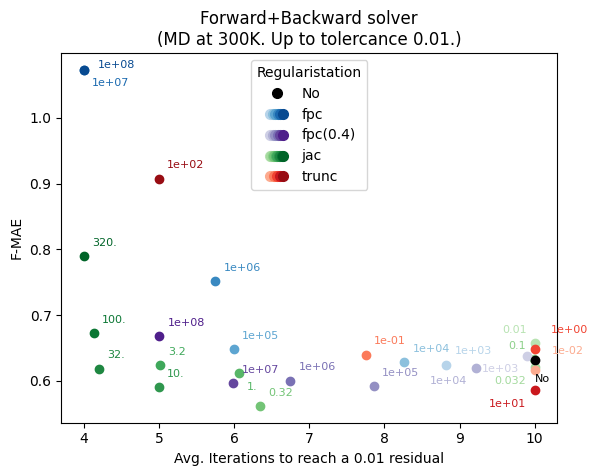

In [107]:
merged = True
# merged = False

cell_postfix = ''
# cell_postfix = '_new'

# r_df, r_tags = runs_df, [mt for mt in runs_df.latest_tag.tolist()
#                             if mt not in [
#                                 'model-qfutzd5y:v659',
#                                 'model-6nf8mqsm:v1075',
#                                 # 'model-7gmda78n:v1829', # good one
#                             ]]
# ws_degrees = [-1, 0, 1]

r_df, r_tags = runs_df_new, runs_df_new.best_manual_tag.tolist()

r_df = runs_df_new
p_cols = ['fpc_gamma', 'fpc_strength', 'jac_reg_strength', 'trunc_strength']
choose_col = '_timestamp'
choose_col = 'val_forces_MAE (at min val_forces_MAE)'
f_df = r_df.sort_values(choose_col).drop_duplicates(p_cols)
r_tags = f_df.best_manual_tag.tolist()

ws_degrees = [-1]

get_colour = partial(get_colour_by_regularisation, runs_df=r_df)
get_label = partial(get_label_by_regularisation, runs_df=r_df)
    

for i, (temp, tol) in enumerate([
    # (500, 0.01),
    (300, 0.01),
]):
    for j, ws in enumerate(ws_degrees):
        postfix = f'_{temp=}K_{tol=}_{ws=}' + '_merged' * merged
        plot_path = '../imlff-paper/figures'
        plot_name = 'losses_to_convergence_speed'
        plot_name_scatter = 'losses_to_convergence_speed_v_fmae_scatter'
        
        legend_loc = None
        if i==0 and j==0:
            legend_loc = 'lower left'
            legend_loc = 'upper center'
        
        (fig,), (axs,), mean_cost_store = convergence_plots(
            data =        [data_both]          if merged else [data_forw, data_back],
            data_labels = ['Forward+Backward'] if merged else ['Forward', 'Backward'],
            
            get_colour = get_colour,
            get_label = get_label, 
            get_linestyle        = get_linestyle,  
            
            run_model_tags_func = lambda mt: mt in r_tags,
            
            temp_tols = [(temp, tol)],
            plot_ws_degrees = [ws],
            seperate_degrees = True,
            show=False,
        )
        
        ## save
        pat = proj_path(f'{plot_path}/{plot_name}{postfix}{cell_postfix}.pdf')
        fig.savefig(pat, bbox_inches="tight")
        ax = axs[0,0]
        title = ax.get_title()
        
        if (i==0 and j==0):
            # save clean copy
            ax.set_title("")
            fig.legends.clear()
            pat = proj_path(f'{plot_path}/{plot_name}{postfix}{cell_postfix}_clean.pdf')
            fig.savefig(pat, bbox_inches="tight")
            print(pat)
            

        
        #### Scatter plot: Crossing 0.01 vs. F-MAE
        scatter_df = create_scatter_df(r_df, mean_cost_store, get_colour=get_colour, get_label=get_label)
        scatter_df.best_manual__test_forces_MAE = scatter_df.best_manual__test_mi10_forces_MAE
        fig, ax = scatter_plot(scatter_df, legend_loc=legend_loc, legend_title='Regularistation')
        
        # copy title
        ax.set_title(title)
        
        ## save
        pat = proj_path(f'{plot_path}/{plot_name_scatter}{postfix}{cell_postfix}.pdf')
        fig.savefig(pat, bbox_inches="tight")
        print(pat)

In [ ]:


f_df.sort_values(p_cols)\
    [p_cols + ['val_forces_MAE (at min val_forces_MAE)', 'best_manual__test_forces_MAE', 'best_manual_tag']]

,fpc_gamma,fpc_strength,jac_reg_strength,trunc_strength,val_forces_MAE (at min val_forces_MAE),best_manual__test_forces_MAE,best_manual_tag
17,0.4,1000.0,NaN,NaN,0.642332,NaN,model-h8hjhaid:v19
30,0.4,10000.0,NaN,NaN,0.633109,NaN,model-vzu4mpzd:v15
24,0.4,100000.0,NaN,NaN,0.604455,NaN,model-shxw1phd:v574
31,0.4,1000000.0,NaN,NaN,0.614973,NaN,model-xs6feire:v374
11,0.4,10000000.0,NaN,NaN,0.601233,NaN,model-85qii01z:v22
32,0.4,100000000.0,NaN,NaN,0.679483,NaN,model-y5y3o1oi:v17
28,1.0,1000.0,NaN,NaN,0.661157,NaN,model-vak5cqic:v419
2,1.0,10000.0,NaN,NaN,0.628885,NaN,model-2brhxooj:v319
6,1.0,100000.0,NaN,NaN,0.683488,NaN,model-4ifpi8o0:v279
20,1.0,1000000.0,NaN,NaN,0.748183,NaN,model-m8zif6kt:v319


### Warmstarts

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined



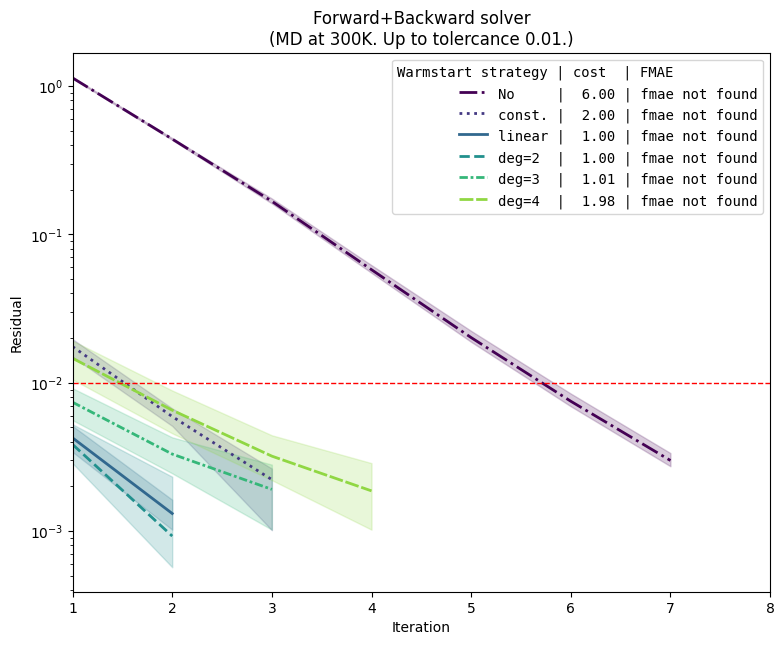

~/imlff/../imlff-paper/figures/warmstarts_to_convergence_speed_temp=300K_tol=0.01_merged.pdf
name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined

name 'best_manual_tag' is not defined



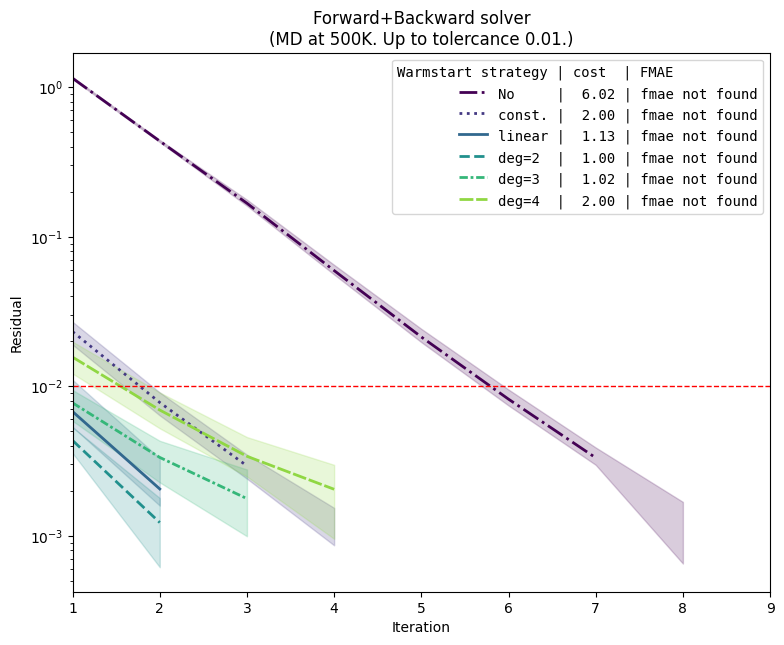

~/imlff/../imlff-paper/figures/warmstarts_to_convergence_speed_temp=500K_tol=0.01_merged.pdf


In [ ]:
merged = True
plot_ws_degrees = [-1,0,1,2,3,4]

for target in [
    # 'qfutzd5y',
    # '6nf',
    # 'model-7gmda78n:v1829', # good one
    '4ehmqw9w',
    ]:
    for temp_tol in [
            (300, 0.01),
            (500, 0.01),
            # (500, 0.  ),
            # (300, 0.  ),
        ]:
        (fig,), (axs,), mean_cost_store = convergence_plots(
            data =        [data_both]          if merged else [data_forw, data_back],
            data_labels = ['Forward+Backward'] if merged else ['Forward', 'Backward'],
            
            temp_tols = [temp_tol],
            
            plot_ws_degrees = plot_ws_degrees,
            # plot_ws_degrees = [0,1],
            # plot_samples = [0, 50, -50, -1],
            
            run_model_tags_func = lambda mt: target in mt,
            
            get_colour = get_colour_by_degree,
            get_label = partial(get_label_by_degree, runs_df=runs_df, warmstart_str=''),
            
            get_linestyle = get_linestyle,
            
            seperate_degrees = False,
            pull_preceding_label_into_legend_title=False,
            
            
            # no_legend = True,
        )
        ## save
        temp, tol = temp_tol
        postfix = f'_{temp=}K_{tol=}' + '_merged'*merged
        pat = proj_path(f'../imlff-paper/figures/warmstarts_to_convergence_speed{postfix}.pdf')
        # fig.savefig(pat, bbox_inches="tight")
        print(pat)
        plt.show()

In [ ]:
scatter_df = create_scatter_df(runs_df, mean_cost_store, get_colour_and_label_deep)
fig, ax = scatter_plot(scatter_df)

### Different models

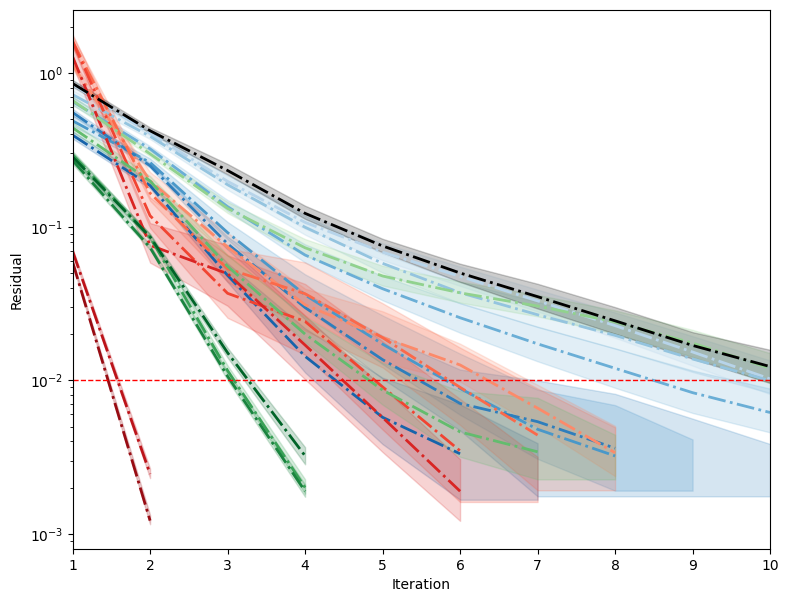

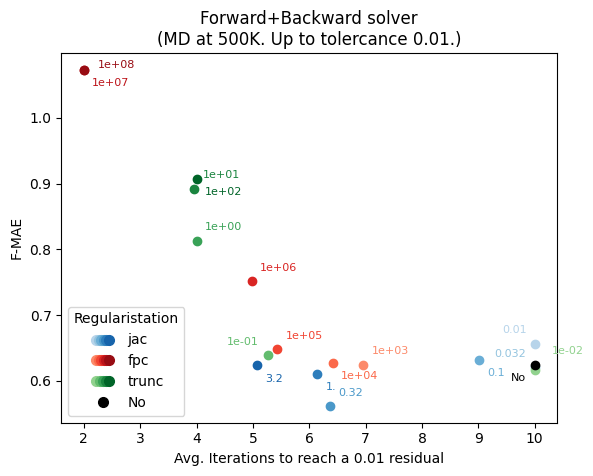

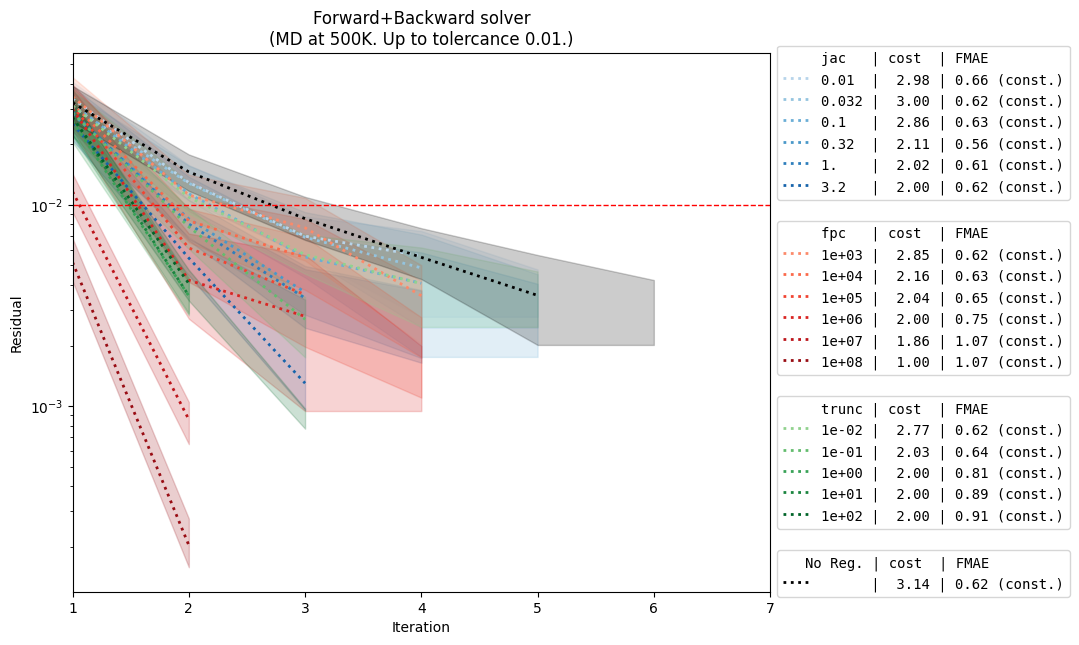

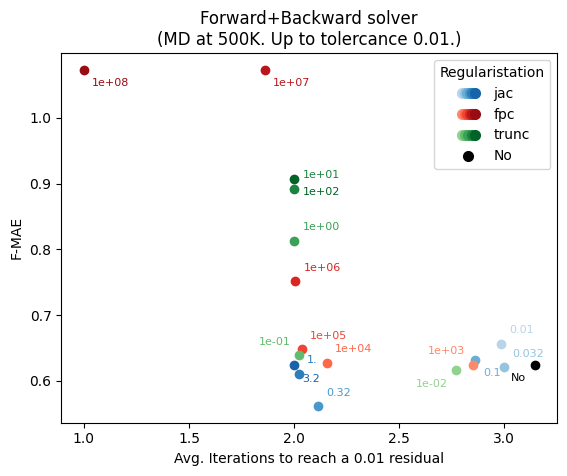

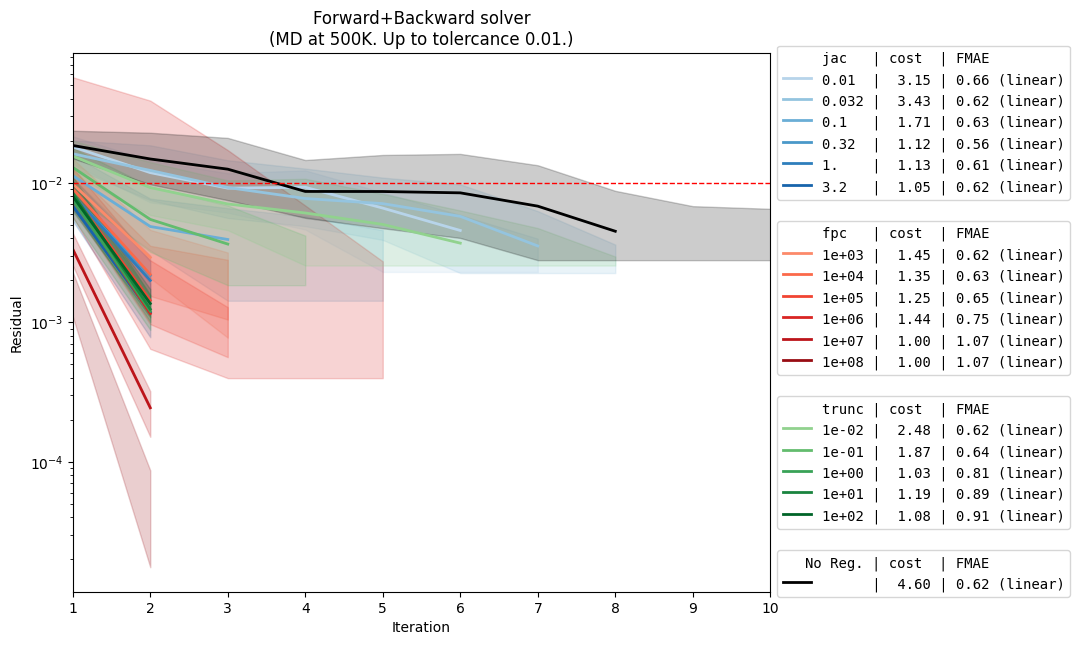

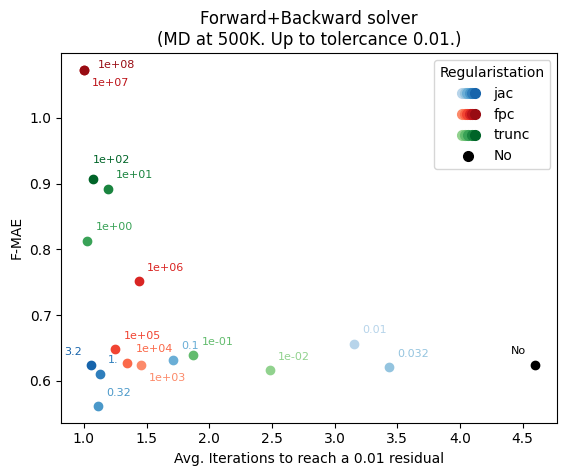

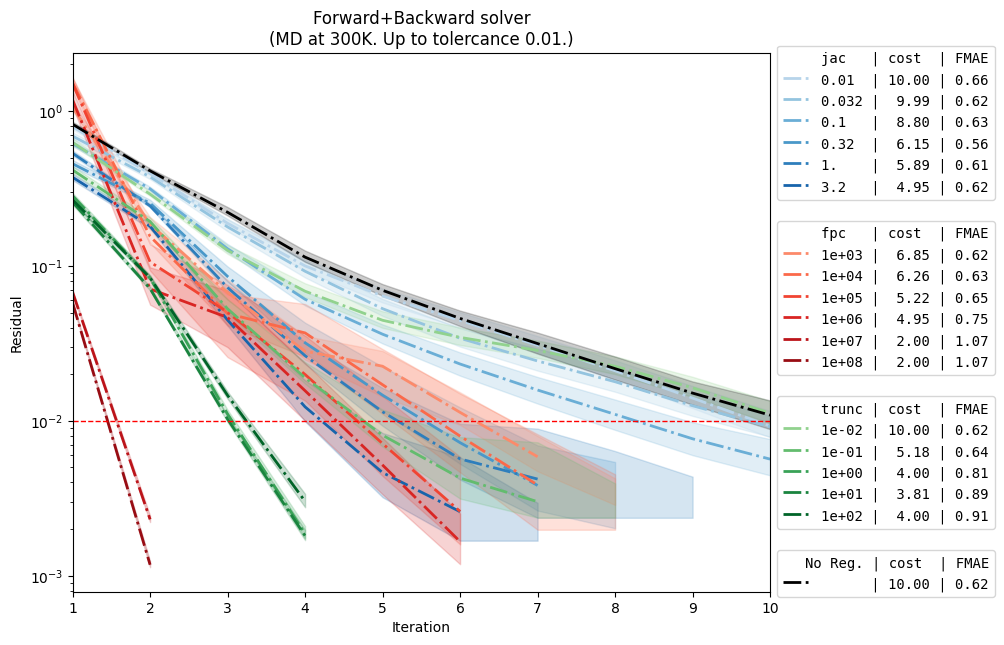

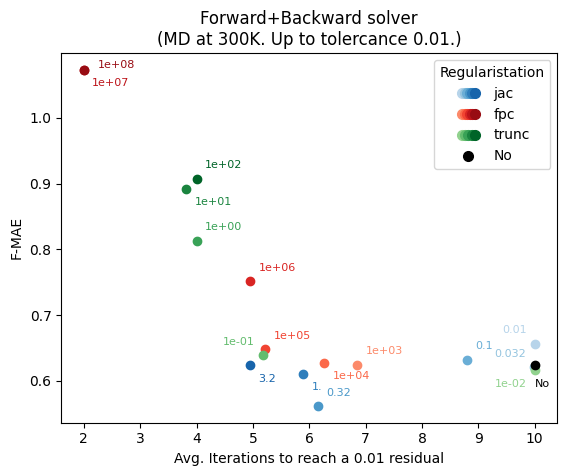

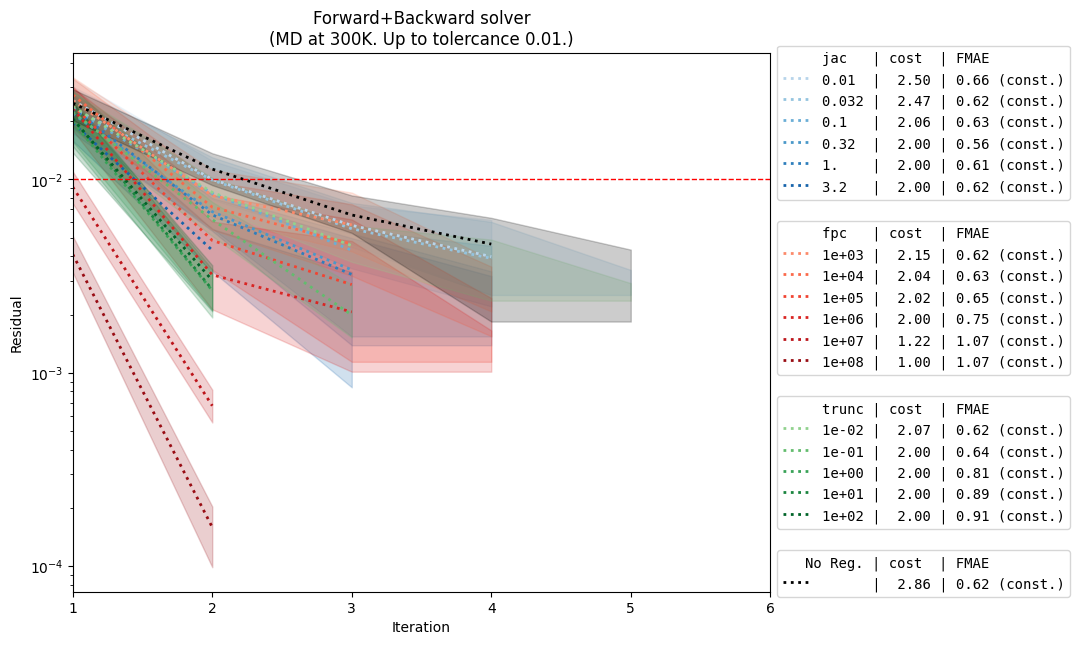

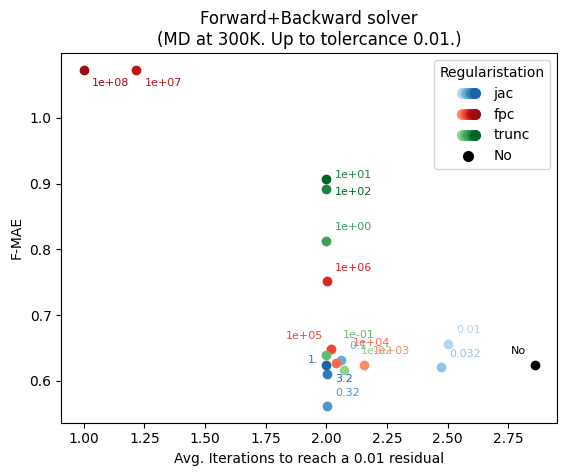

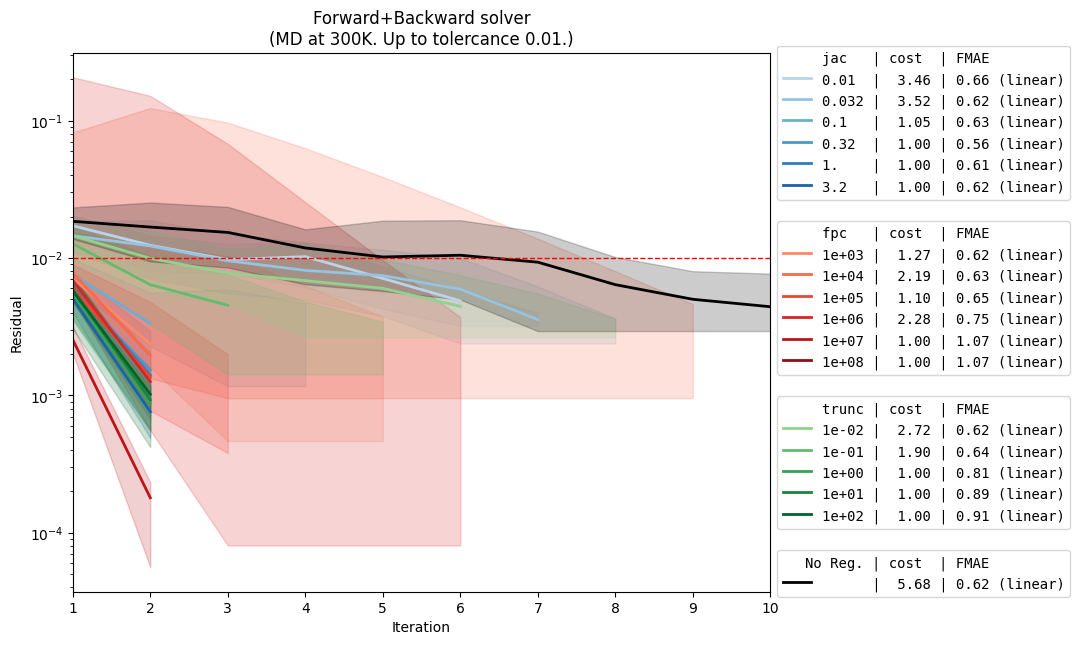

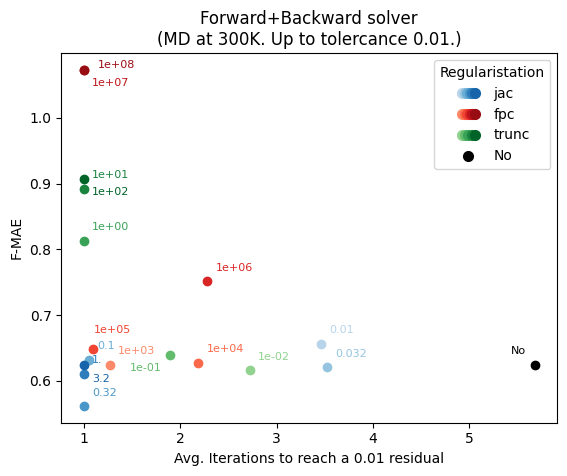

In [ ]:
merged = True
# merged = False

def run_model_tags_func(mt):
    # if mt not in runs_df[runs_df.jac_reg_strength>0].latest_tag.tolist():
    #     return False
    
    # exclude bad jac_reg==.32 models
    if mt in [
        'model-qfutzd5y:v659',
        'model-6nf8mqsm:v1075',
        # 'model-7gmda78n:v1829', # good one
        ]:
        return False
    
    if mt not in runs_df.latest_tag.tolist():
        return False
    
    return True
    

for i, (temp, tol) in enumerate([
    (500, 0.01),
    (300, 0.01),
]):
    for j, ws in enumerate([-1, 0, 1]):
        postfix = f'_{temp=}K_{tol=}_{ws=}' + '_merged' * merged
        plot_path = '../imlff-paper/figures'
        plot_name = 'losses_to_convergence_speed'
        plot_name_scatter = 'losses_to_convergence_speed_v_fmae_scatter'
        
        legend_loc = None
        if i==0 and j==0:
            legend_loc = 'lower left'
        
        (fig,), (axs,), mean_cost_store = convergence_plots(
            data =        [data_both]          if merged else [data_forw, data_back],
            data_labels = ['Forward+Backward'] if merged else ['Forward', 'Backward'],
            
            get_colour = get_colour,
            get_label = get_label, 
            get_linestyle        = get_linestyle,  
            
            run_model_tags_func = run_model_tags_func,
            
            temp_tols = [(temp, tol)],
            plot_ws_degrees = [ws],
            seperate_degrees = True,
            show=False,
        )
        
        ## save
        pat = proj_path(f'{plot_path}/{plot_name}{postfix}.pdf')
        fig.savefig(pat, bbox_inches="tight")
        ax = axs[0,0]
        title = ax.get_title()
        
        if (i==0 and j==0):
            # save clean copy
            ax.set_title("")
            fig.legends.clear()
            pat = proj_path(f'{plot_path}/{plot_name}{postfix}_clean.pdf')
            fig.savefig(pat, bbox_inches="tight")
            

        
        #### Scatter plot: Crossing 0.01 vs. F-MAE
        scatter_df = create_scatter_df(runs_df, mean_cost_store, get_colour=get_colour)
        fig, ax = scatter_plot(scatter_df, legend_loc=legend_loc, legend_title='Regularistation')
        
        # copy title
        ax.set_title(title)
        
        ## save
        pat = proj_path(f'{plot_path}/{plot_name_scatter}{postfix}.pdf')
        fig.savefig(pat, bbox_inches="tight")